In [1]:
# Machine Learning Library
import pandas as pd
import numpy as np
import pickle
import nltk
import re
from nltk.stem import PorterStemmer
import seaborn as sns
import matplotlib.pyplot as plt
from wordcloud import WordCloud
from sklearn.preprocessing import LabelEncoder
plt.style.use('ggplot')

In [2]:
# Deep Learning Library
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.preprocessing.text import one_hot
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.utils import to_categorical

In [3]:
train_data = pd.read_csv("train.txt", header = None, sep=";", names=["Comment", "Emotion"], encoding="utf-8")

In [4]:
train_data['length'] = [len(x) for x in train_data['Comment']]

In [5]:
train_data.head()

,Comment,Emotion,length
0,i didnt feel humiliated,sadness,23
1,i can go from feeling so hopeless to so damned...,sadness,108
2,im grabbing a minute to post i feel greedy wrong,anger,48
3,i am ever feeling nostalgic about the fireplac...,love,92
4,i am feeling grouchy,anger,20


In [6]:
train_data.shape

(16000, 3)

In [7]:
train_data.isnull().sum()

Comment    0
Emotion    0
length     0
dtype: int64

In [8]:
train_data.duplicated().sum()

np.int64(1)

In [9]:
# EDA

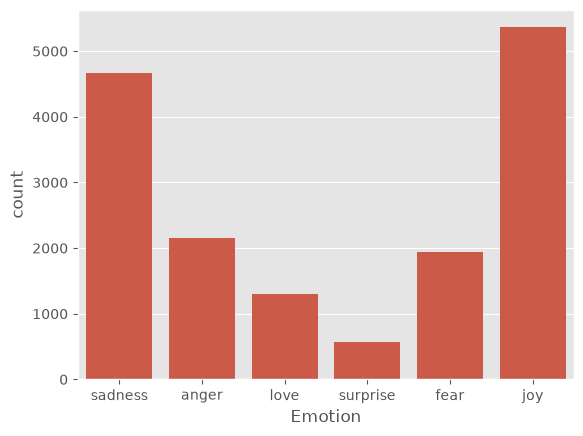

In [10]:
sns.countplot(x=train_data['Emotion'])
plt.show()

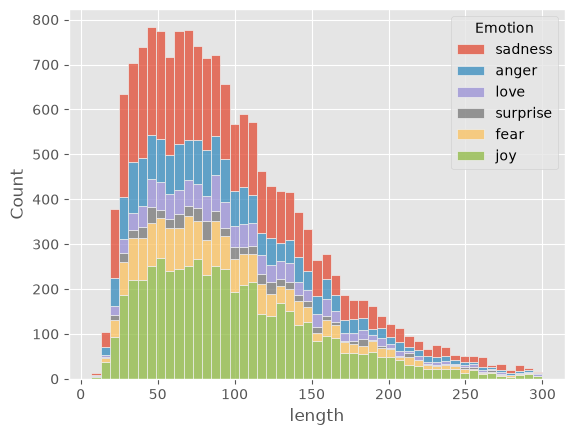

In [11]:
df2 = train_data.copy()
df2['length'] = [len(x) for x in train_data['Comment']]
length_value = df2['length'].values
sns.histplot(data=df2, x='length',hue='Emotion',multiple = 'stack')
plt.show()

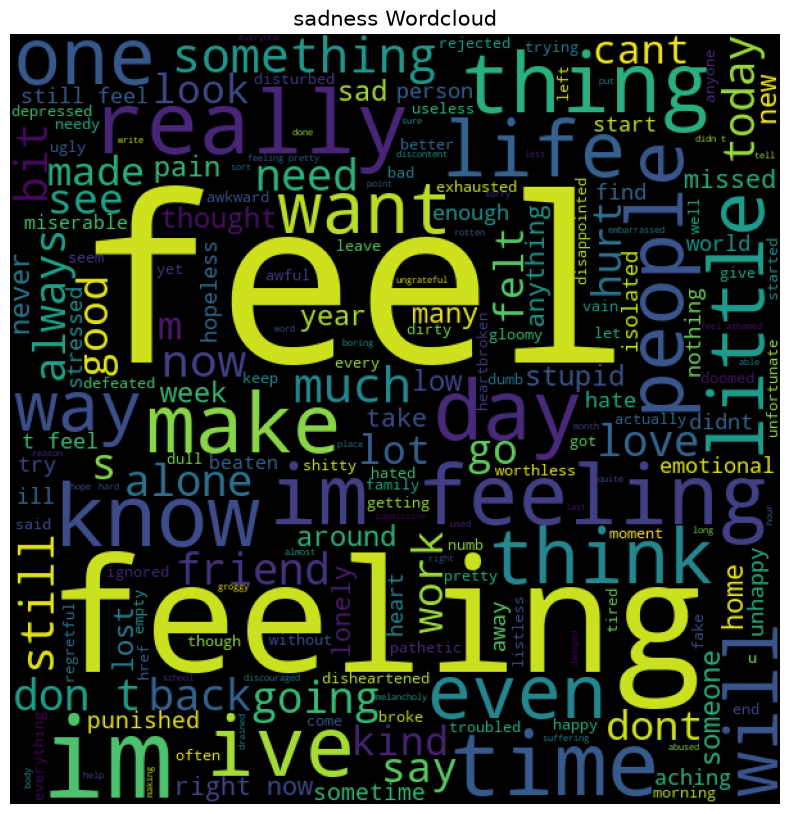

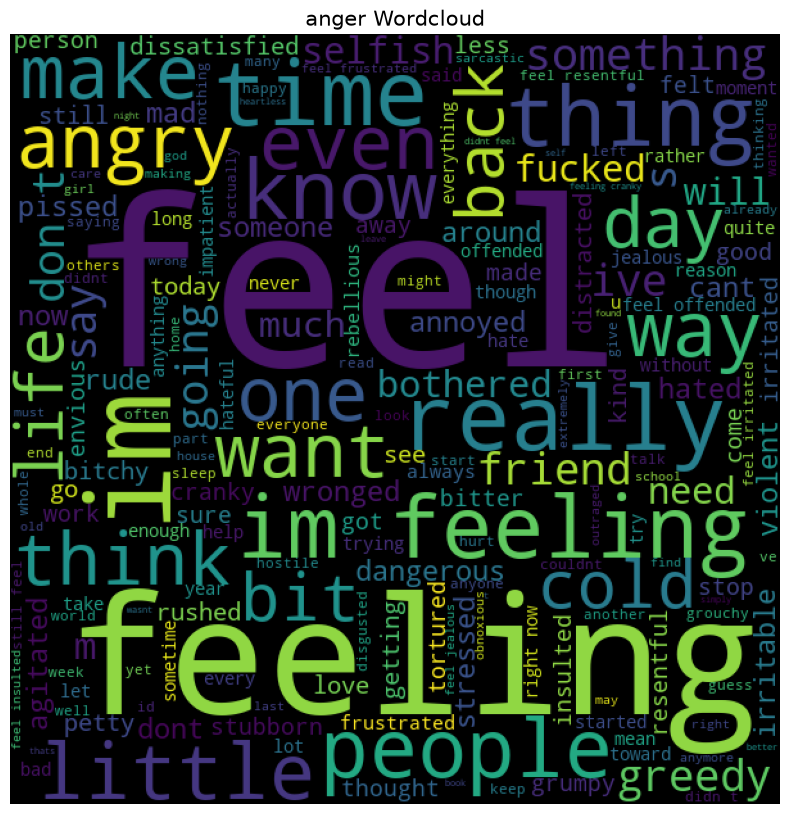

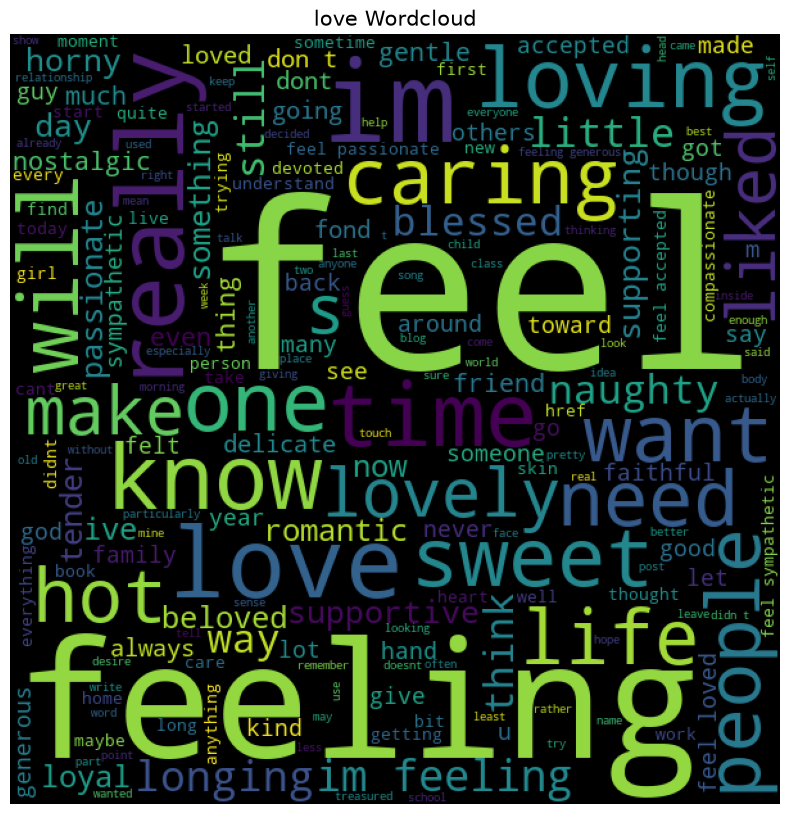

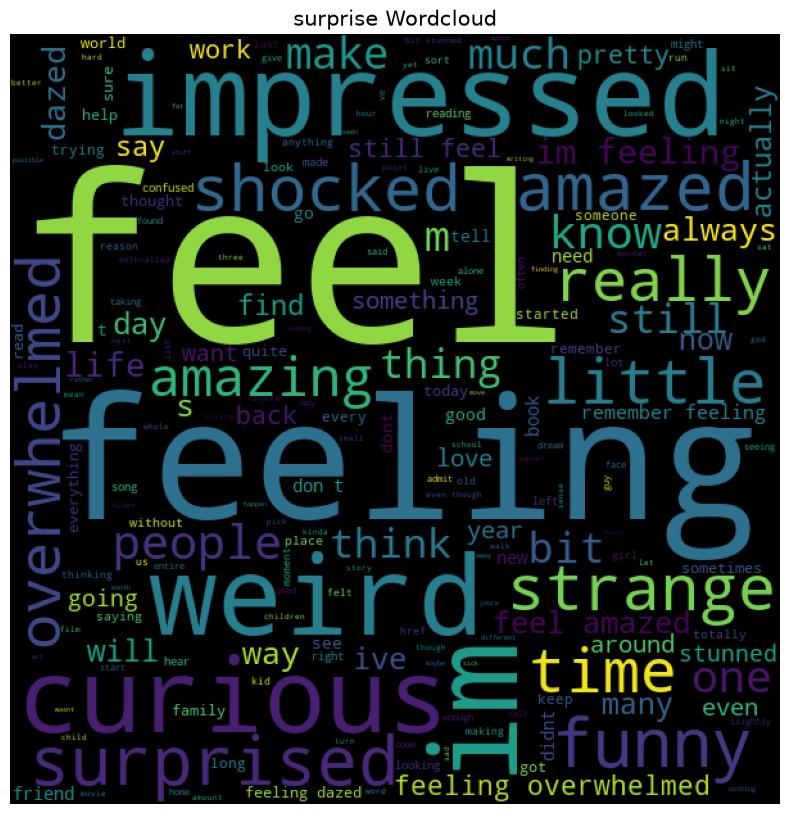

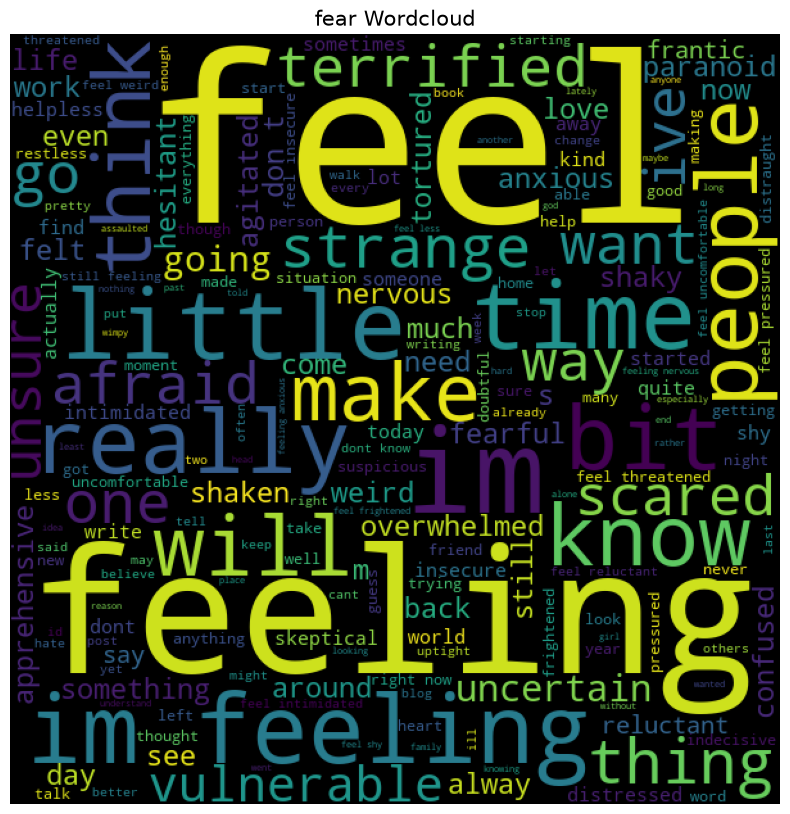

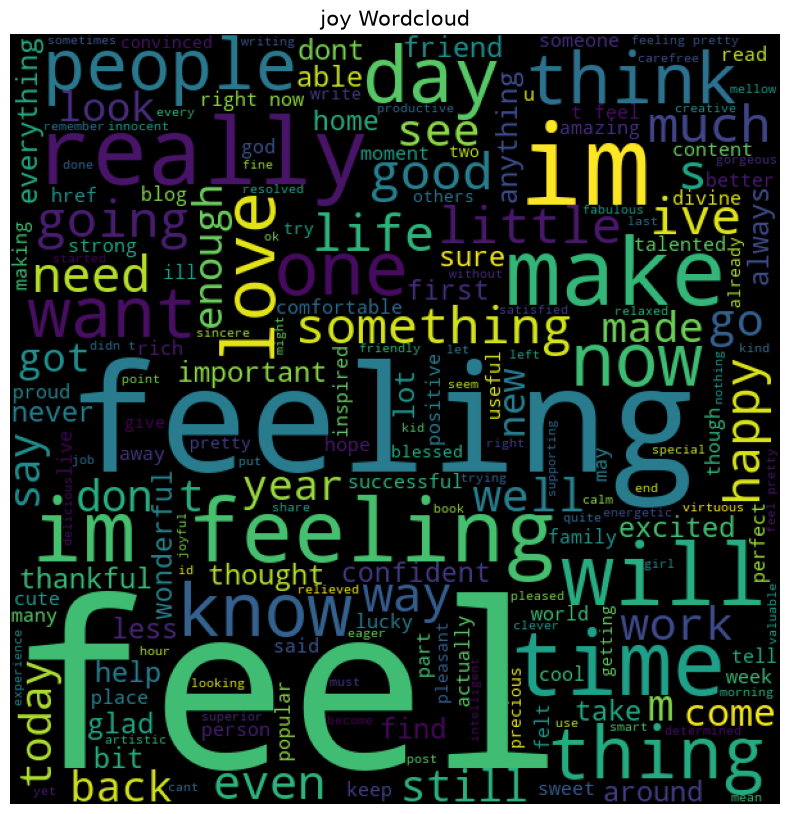

In [12]:
def words_cloud(wordcloud, df):
    plt.figure(figsize=(10,10))
    plt.title(df + ' Wordcloud', size = 15)
    plt.imshow(wordcloud)
    plt.axis("off")
emotions_list = train_data['Emotion'].unique()
for emotion in emotions_list:
    text = ' '.join([sentence for sentence in train_data.loc[train_data['Emotion'] == emotion,'Comment']])
    wordcloud = WordCloud(width = 600, height = 600).generate(text)
    words_cloud(wordcloud, emotion)

In [13]:
# Data preprocessing

In [14]:
lb = LabelEncoder()
train_data['Emotion'] = lb.fit_transform(train_data['Emotion'])

In [15]:
train_data.head()

,Comment,Emotion,length
0,i didnt feel humiliated,4,23
1,i can go from feeling so hopeless to so damned...,4,108
2,im grabbing a minute to post i feel greedy wrong,0,48
3,i am ever feeling nostalgic about the fireplac...,3,92
4,i am feeling grouchy,0,20


In [16]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report

In [17]:
df = train_data.copy()

In [18]:
df.head()

,Comment,Emotion,length
0,i didnt feel humiliated,4,23
1,i can go from feeling so hopeless to so damned...,4,108
2,im grabbing a minute to post i feel greedy wrong,0,48
3,i am ever feeling nostalgic about the fireplac...,3,92
4,i am feeling grouchy,0,20


In [19]:
from tqdm import tqdm
tqdm.pandas()
nltk.download('stopwords')
stopwords = set(nltk.corpus.stopwords.words('english'))

def clean_data(text):
    stemmer = PorterStemmer()
    text = re.sub("[^a-zA-Z]", " ",text)
    text = text.lower()
    text = text.split()
    text = [stemmer.stem(word) for word in text if word not in stopwords]
    return " ".join(text)

df['cleaned_comment']  = df['Comment'].progress_apply(clean_data)
# df['cleaned_comment']  = df['Comment'].apply(clean_data) 

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\PARTH\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
100%|██████████| 16000/16000 [00:03<00:00, 4820.35it/s]


In [20]:
df.head()

,Comment,Emotion,length,cleaned_comment
0,i didnt feel humiliated,4,23,didnt feel humili
1,i can go from feeling so hopeless to so damned...,4,108,go feel hopeless damn hope around someon care ...
2,im grabbing a minute to post i feel greedy wrong,0,48,im grab minut post feel greedi wrong
3,i am ever feeling nostalgic about the fireplac...,3,92,ever feel nostalg fireplac know still properti
4,i am feeling grouchy,0,20,feel grouchi


In [21]:
X_train, X_test, y_train, y_test = train_test_split(df['cleaned_comment'], df['Emotion'], test_size = 0.2, random_state=42)

In [22]:
tfidfvectorizer = TfidfVectorizer()
X_train_tfidf = tfidfvectorizer.fit_transform(X_train)
X_test_tfidf = tfidfvectorizer.transform(X_test)

In [23]:
X_train_tfidf.shape

(12800, 9257)

In [24]:
classifier={
    'MultinomialNB':MultinomialNB(),
    'LogisticRegression':LogisticRegression(),
    'Random Forest':RandomForestClassifier(),
    'Support Vector Machine': SVC(),
}

for name,clf in classifier.items():
    print(f"\n============{name}============")
    clf.fit(X_train_tfidf, y_train)
    y_pred_tfidf = clf.predict(X_test_tfidf)
    accuracy_tfidf = accuracy_score(y_test, y_pred_tfidf)
    print(f"======={accuracy_tfidf}============")
    print("Classification Report")
    print(classification_report(y_test, y_pred_tfidf))


============MultinomialNB============
=======0.655============
Classification Report
              precision    recall  f1-score   support

           0       0.93      0.31      0.46       427
           1       0.91      0.24      0.38       397
           2       0.58      0.98      0.73      1021
           3       1.00      0.03      0.06       296
           4       0.70      0.91      0.79       946
           5       1.00      0.01      0.02       113

    accuracy                           0.66      3200
   macro avg       0.85      0.41      0.41      3200
weighted avg       0.76      0.66      0.58      3200


============LogisticRegression============
=======0.829375============
Classification Report
              precision    recall  f1-score   support

           0       0.88      0.79      0.83       427
           1       0.84      0.73      0.78       397
           2       0.78      0.94      0.85      1021
           3       0.80      0.49      0.61       296
      

In [25]:
#Random Forest
lg = LogisticRegression()
lg.fit(X_train_tfidf, y_train)
lg_y_pred = lg.predict(X_test_tfidf)

In [26]:
def predict_emotion(input_text):
    cleaned_text = clean_data(input_text)
    input_vectorizer = tfidfvectorizer.transform([cleaned_text])
    
    predicted_label = lg.predict(input_vectorizer)[0]
    predicted_emotion = lb.inverse_transform([predicted_label])[0]
    label = np.max(lg.predict(input_vectorizer))
    
    return predicted_emotion, label

In [27]:
predict_emotion("She breakup with me")

('sadness', np.int64(4))

In [28]:
import pickle
pickle.dump(lg, open("logistic_regression.pkl","wb"))
pickle.dump(lb, open("label_encoder.pkl","wb"))
pickle.dump(tfidfvectorizer, open("tfidfvectorizer.pkl","wb"))

In [29]:
# APPLYING DEEP LEARNING USING LSTM(LONG SHORT TERM MEMORY)

In [30]:
def text_cleaning(df, column, vocab_size, max_len):
    stemmer = PorterStemmer()
    corpus = []
    for text in df[column]:
        text = re.sub("[^a-zA-Z]", " ",text)
        text = text.lower()
        text = text.split()
        text = [stemmer.stem(word) for word in text if word not in stopwords]
        text = " ".join(text)
        corpus.append(text)
    one_hot_word = [one_hot(input_text=word, n=vocab_size) for word in corpus]
    pad = pad_sequences(sequences=one_hot_word, maxlen=max_len, padding="pre")
    return pad

In [31]:
# Prepare data specifically for the LSTM model
# Emotion was already encoded in train_data above using lb.
from sklearn.model_selection import train_test_split
from tensorflow.keras.utils import to_categorical

VOCAB_SIZE = 11000
MAX_LEN = 300
NUM_CLASSES = len(lb.classes_)

# Keep a held-out test set for evaluation
X_text_train, X_text_test, y_train_labels, y_test_labels = train_test_split(
    train_data["Comment"],
    train_data["Emotion"],
    test_size=0.2,
    random_state=42,
    stratify=train_data["Emotion"]
)

# Convert text to padded integer sequences using the text_cleaning function above
x_train = text_cleaning(
    pd.DataFrame({"Comment": X_text_train}),
    "Comment",
    vocab_size=VOCAB_SIZE,
    max_len=MAX_LEN
)
x_test = text_cleaning(
    pd.DataFrame({"Comment": X_text_test}),
    "Comment",
    vocab_size=VOCAB_SIZE,
    max_len=MAX_LEN
)

# Convert integer class labels to one-hot vectors for categorical_crossentropy
y_train = to_categorical(y_train_labels.to_numpy(), num_classes=NUM_CLASSES)
y_test = to_categorical(y_test_labels.to_numpy(), num_classes=NUM_CLASSES)

print("x_train shape:", x_train.shape)
print("y_train shape:", y_train.shape)
print("x_test shape:", x_test.shape)
print("y_test shape:", y_test.shape)
print("Number of emotion classes:", NUM_CLASSES)

x_train shape: (12800, 300)
y_train shape: (12800, 6)
x_test shape: (3200, 300)
y_test shape: (3200, 6)
Number of emotion classes: 6


In [32]:
model = Sequential()
model.add(Embedding(input_dim = 11000, output_dim = 150, input_length = 300))
model.add(Dropout(0.2))
model.add(LSTM(128))
model.add(Dropout(0.2))
model.add(Dense(64, activation = 'sigmoid'))
model.add(Dropout(0.2))
model.add(Dense(6, activation = 'softmax'))

c:\Users\PARTH\anaconda3\envs\tf_clean\Lib\site-packages\keras\src\layers\core\embedding.py:123: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


In [33]:
model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

callback = EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

history = model.fit(
    x_train,
    y_train,
    epochs=10,
    batch_size=64,
    verbose=1,
    validation_split=0.2,
    callbacks=[callback]
)

# Evaluate once on the held-out test set
test_loss, test_accuracy = model.evaluate(x_test, y_test, verbose=1)
print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.4f}")

Epoch 1/10
160/160 ━━━━━━━━━━━━━━━━━━━━ 62s 370ms/step - accuracy: 0.3156 - loss: 1.6358 - val_accuracy: 0.3645 - val_loss: 1.5573
Epoch 2/10
160/160 ━━━━━━━━━━━━━━━━━━━━ 55s 344ms/step - accuracy: 0.5305 - loss: 1.3274 - val_accuracy: 0.5969 - val_loss: 1.1239
Epoch 3/10
160/160 ━━━━━━━━━━━━━━━━━━━━ 56s 352ms/step - accuracy: 0.7017 - loss: 0.8331 - val_accuracy: 0.7527 - val_loss: 0.7350
Epoch 4/10
160/160 ━━━━━━━━━━━━━━━━━━━━ 54s 340ms/step - accuracy: 0.8376 - loss: 0.5257 - val_accuracy: 0.8305 - val_loss: 0.5500
Epoch 5/10
160/160 ━━━━━━━━━━━━━━━━━━━━ 54s 341ms/step - accuracy: 0.8996 - loss: 0.3446 - val_accuracy: 0.8453 - val_loss: 0.4968
Epoch 6/10
160/160 ━━━━━━━━━━━━━━━━━━━━ 55s 343ms/step - accuracy: 0.9300 - loss: 0.2451 - val_accuracy: 0.8551 - val_loss: 0.4948
Epoch 7/10
160/160 ━━━━━━━━━━━━━━━━━━━━ 55s 343ms/step - accuracy: 0.9471 - loss: 0.1873 - val_accuracy: 0.8586 - val_loss: 0.4946
Epoch 8/10
160/160 ━━━━━━━━━━━━━━━━━━━━ 55s 342ms/step - accuracy: 0.9579 - loss: 0

In [34]:
# Machine Learning

In [35]:
model.save("model.keras")

In [36]:
from keras.models import load_model
model01 = load_model("model.keras")

In [37]:
def predictive_system_dl(sentence):
    stemmer = PorterStemmer()
    corpus = []
    text = re.sub("[^a-zA-Z]", " ",sentence)
    text = text.lower()
    text = text.split()
    text = [stemmer.stem(word) for word in text if word not in stopwords]
    text = " ".join(text)
    corpus.append(text)
    one_hot_word = [one_hot(input_text=word, n=11000) for word in corpus]
    pad = pad_sequences(sequences=one_hot_word, maxlen=300, padding="pre")
    return pad

In [38]:
sentence = predictive_system_dl("Iam feeling love with you")
result = lb.inverse_transform(np.argmax(model.predict(sentence), axis = 1))[0]
prob = np.max(model01.predict(sentence))
print(f"{result} with probability of {prob}")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 226ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 224ms/step
love with probability of 0.8568412661552429


In [39]:
with open("lb1.pkl","wb") as f:
    pickle.dump(lb,f)
vocab_info = {"vocab_size": 11000, "max_len":300}
with open("vocab_info.pkl","wb") as f:
    pickle.dump(vocab_info, f)